In [ ]:
!pip install -q ucimlrepo scikit-learn pandas numpy matplotlib joblib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import json
import re
import ipaddress

from urllib.parse import urlparse
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
dataset = fetch_ucirepo(id=967)

X_raw = dataset.data.features
y_raw = dataset.data.targets

print("Dataset loaded successfully!")
print("Feature columns:", list(X_raw.columns))
print("Target columns:", list(y_raw.columns))
print("Original dataset shape:", X_raw.shape)

Dataset loaded successfully!
Feature columns: ['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']
Target columns: ['label']
Original dataset shape: (23579

Cleaned dataset shape: (235370, 2)

Class distribution:
label
Legitimate    134850
Phishing      100520
Name: count, dtype: int64


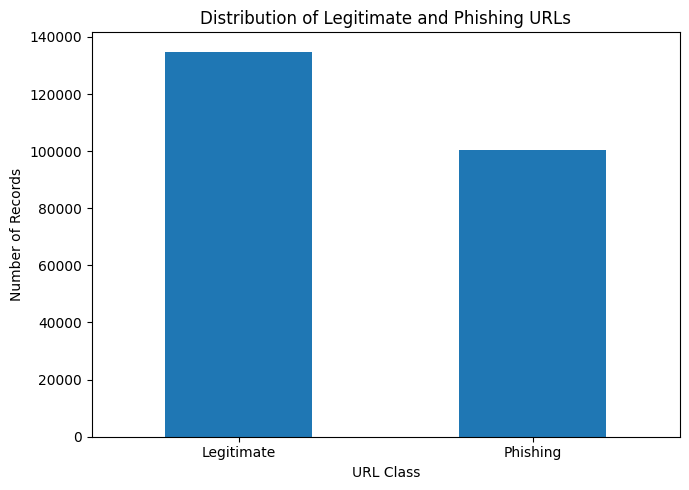

In [ ]:
url_column = next(
    col for col in X_raw.columns
    if str(col).strip().lower() == "url"
)

target_column = next(
    (col for col in y_raw.columns
     if str(col).strip().lower()
     in {"label", "result", "target", "class"}),
    y_raw.columns[0] if y_raw.shape[1] == 1 else None
)

if target_column is None:
    raise ValueError("Could not identify the target column.")

data = pd.DataFrame({
    "url": X_raw[url_column],
    "label": y_raw[target_column]
})

data = data.dropna()
data = data.drop_duplicates(subset=["url"]).reset_index(drop=True)

data["label"] = pd.to_numeric(data["label"], errors="coerce")
data = data[data["label"].isin([0, 1])].copy()

# Source dataset: 0 = phishing, 1 = legitimate.
# Our project: 1 = phishing, 0 = legitimate.
data["label"] = (data["label"] == 0).astype(int)

print("Cleaned dataset shape:", data.shape)
print("\nClass distribution:")
print(data["label"].value_counts().rename(
    index={0: "Legitimate", 1: "Phishing"}
))

class_counts = data["label"].map({
    0: "Legitimate",
    1: "Phishing"
}).value_counts()

plt.figure(figsize=(7, 5))
class_counts.plot(kind="bar")
plt.title("Distribution of Legitimate and Phishing URLs")
plt.xlabel("URL Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
class DataValidationError(Exception):
    """Raised when the dataset or the feature matrix violates an expectation."""

def validate_clean_dataset(df):
    """Validation checks for the cleaned (url, label) dataset. Returns the list of passed checks."""
    problems = []
    if not {"url", "label"}.issubset(df.columns):
        raise DataValidationError("Columns 'url' and 'label' are required.")
    if len(df) == 0:
        raise DataValidationError("Dataset is empty after cleaning.")
    if df[["url", "label"]].isna().any().any():
        problems.append("missing values present")
    if df["url"].duplicated().any():
        problems.append("duplicate URLs present")
    if not set(df["label"].unique()).issubset({0, 1}):
        problems.append("label contains values other than 0/1")
    if df["label"].nunique() < 2:
        problems.append("only one class present")
    if (df["url"].astype(str).str.strip() == "").any():
        problems.append("empty URL strings present")
    minority = df["label"].value_counts(normalize=True).min()
    if minority < 0.05:
        problems.append(f"severe class imbalance (minority = {minority:.1%})")
    if problems:
        raise DataValidationError("; ".join(problems))
    return ["no missing values", "no duplicate URLs", "binary labels",
            "both classes present", "no empty URLs", "acceptable class balance"]

print("Dataset validation passed:", ", ".join(validate_clean_dataset(data)))

# dataset summary (for the report)
print("\nRaw records            :", len(X_raw))
print("Raw features           :", X_raw.shape[1])
print("Missing values (raw)   :", int(X_raw.isna().sum().sum()))
print("Duplicate URLs (raw)   :", int(X_raw[url_column].duplicated().sum()))
print("Records after cleaning :", len(data))

Dataset validation passed: no missing values, no duplicate URLs, binary labels, both classes present, no empty URLs, acceptable class balance

Raw records            : 235795
Raw features           : 54
Missing values (raw)   : 0
Duplicate URLs (raw)   : 425
Records after cleaning : 235370


In [ ]:
import math, time
from collections import Counter

SUSPICIOUS_KEYWORDS = (
    "login", "signin", "verify", "secure", "account", "update", "bank", "confirm",
    "password", "paypal", "wallet", "billing", "support", "free", "bonus", "alert"
)
SUSPICIOUS_TLDS = {
    "xyz", "top", "tk", "ml", "ga", "cf", "gq", "click", "link", "zip",
    "work", "support", "rest", "buzz", "icu", "monster", "cyou"
}

def _entropy(text):
    if not text:
        return 0.0
    counts = Counter(text)
    n = len(text)
    return -sum((c / n) * math.log2(c / n) for c in counts.values())

def extract_url_features(url):
    """Convert one URL string into a dictionary of numeric features."""
    url = str(url).strip()
    target = url if "://" in url else "http://" + url

    try:
        parsed = urlparse(target)
        host = (parsed.hostname or "").lower()
        path = parsed.path or ""
        query = parsed.query or ""
        has_port = int(parsed.port is not None)
    except ValueError:                      # malformed URL -> neutral values
        host, path, query, has_port = "", "", "", 0

    try:
        ipaddress.ip_address(host)
        is_ip = 1
    except ValueError:
        is_ip = 0

    labels = [l for l in host.split(".") if l]
    if is_ip or len(labels) < 2:
        tld, subdomains = "", 0
    else:
        tld = labels[-1]
        subdomains = len([l for l in labels[:-2] if l != "www"])

    n = max(len(url), 1)
    lower = url.lower()
    letters = sum(c.isalpha() for c in url)
    digits = sum(c.isdigit() for c in url)
    other_special = sum((not c.isalnum()) and c not in "=?&" for c in url)
    encoded = len(re.findall(r"%[0-9a-fA-F]{2}", url))
    tokens = re.split(r"[^A-Za-z0-9]+", url)

    return {
        "url_length": len(url),
        "domain_length": len(host),
        "is_domain_ip": is_ip,
        "num_subdomains": subdomains,
        "tld_length": len(tld),
        "has_suspicious_tld": int(tld in SUSPICIOUS_TLDS),
        "has_www": int(bool(labels) and labels[0] == "www"),
        "num_dots": url.count("."),
        "num_hyphens_url": url.count("-"),
        "num_hyphens_domain": host.count("-"),
        "num_digits": digits,
        "digit_ratio": digits / n,
        "digits_in_domain": sum(c.isdigit() for c in host),
        "num_letters": letters,
        "letter_ratio": letters / n,
        "num_equals": url.count("="),
        "num_qmark": url.count("?"),
        "num_ampersand": url.count("&"),
        "num_other_special": other_special,
        "special_char_ratio": other_special / n,
        "is_https": int(lower.startswith("https://")),
        "has_at_symbol": int("@" in url),
        "num_encoded_chars": encoded,
        "has_obfuscation": int(encoded > 0),
        "obfuscation_ratio": encoded * 3 / n,
        "has_port": has_port,
        "path_length": len(path),
        "num_path_segments": len([p for p in path.split("/") if p]),
        "query_length": len(query),
        "double_slash_in_path": int("//" in path),
        "suspicious_keyword_count": sum(lower.count(k) for k in SUSPICIOUS_KEYWORDS),
        "url_entropy": _entropy(url),
        "longest_token_length": max(len(t) for t in tokens),
    }

FEATURE_NAMES = list(extract_url_features("http://example.com").keys())

def make_feature_frame(urls):
    """Convert an iterable of URLs into a numeric DataFrame with FEATURE_NAMES columns."""
    rows = [extract_url_features(u) for u in urls]
    return pd.DataFrame(rows, columns=FEATURE_NAMES).astype(float)

def validate_feature_frame(frame):
    """Validation of the engineered feature matrix."""
    if list(frame.columns) != FEATURE_NAMES:
        raise DataValidationError("Feature columns do not match FEATURE_NAMES (order matters).")
    if frame.isna().any().any():
        raise DataValidationError("Feature matrix contains NaN values.")
    if not np.isfinite(frame.to_numpy()).all():
        raise DataValidationError("Feature matrix contains infinite values.")
    if (frame < 0).any().any():
        raise DataValidationError("Feature matrix contains negative values.")
    ratio_cols = [c for c in frame.columns if c.endswith("_ratio")]
    if (frame[ratio_cols] > 1.0 + 1e-9).any().any():
        raise DataValidationError("A ratio feature is greater than 1.")
    return True

t0 = time.perf_counter()
X = make_feature_frame(data["url"])
y = data["label"].reset_index(drop=True)
print(f"Feature matrix: {X.shape} built in {time.perf_counter() - t0:.1f} s")

validate_feature_frame(X)
print("Feature validation passed: correct columns, no NaN / inf / negative values.")

Feature matrix: (235370, 33) built in 17.7 s
Feature validation passed: correct columns, no NaN / inf / negative values.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 188296
Testing records: 47074


In [ ]:
TEST_SIZE = 0.20

if set(X_train.index) & set(X_test.index):
    raise DataValidationError("Train and test sets overlap (data leakage).")
if abs(len(X_test) / len(X) - TEST_SIZE) > 0.01:
    raise DataValidationError("Test-set size differs from the configured ratio.")
if abs(y_train.mean() - y_test.mean()) > 0.005:
    raise DataValidationError("Split is not stratified - class ratios differ.")

print(f"Phishing share -> train: {y_train.mean():.3%} | test: {y_test.mean():.3%}")
print("Split validation passed: no leakage, correct ratio, stratified.")

Phishing share -> train: 42.707% | test: 42.707%
Split validation passed: no leakage, correct ratio, stratified.


Training: Logistic Regression
Accuracy: 0.9978
Precision: 0.9998
Recall: 0.995
F1-score: 0.9974
----------------------------------------
Training: Decision Tree
Accuracy: 0.9981
Precision: 0.9996
Recall: 0.996
F1-score: 0.9978
----------------------------------------
Training: Random Forest
Accuracy: 0.9982
Precision: 0.9999
Recall: 0.996
F1-score: 0.9979
----------------------------------------
All models trained successfully!


,model,accuracy,precision,recall,f1_score,roc_auc
0,Logistic Regression,0.9978,0.9998,0.995,0.9974,0.9988
1,Decision Tree,0.9981,0.9996,0.996,0.9978,0.9981
2,Random Forest,0.9982,0.9999,0.996,0.9979,0.9986


Best model: Random Forest
Best F1-score: 0.9979


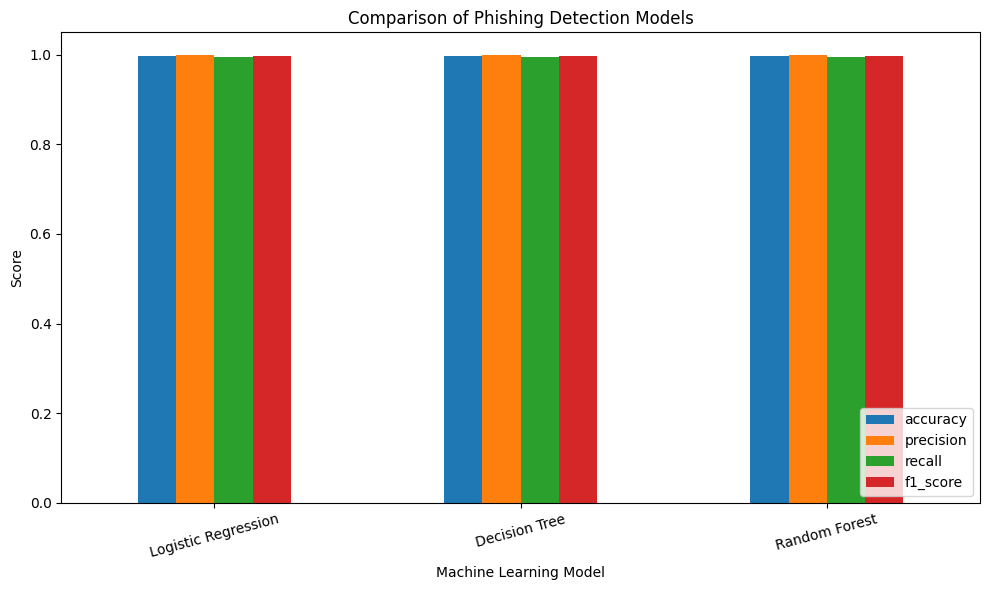

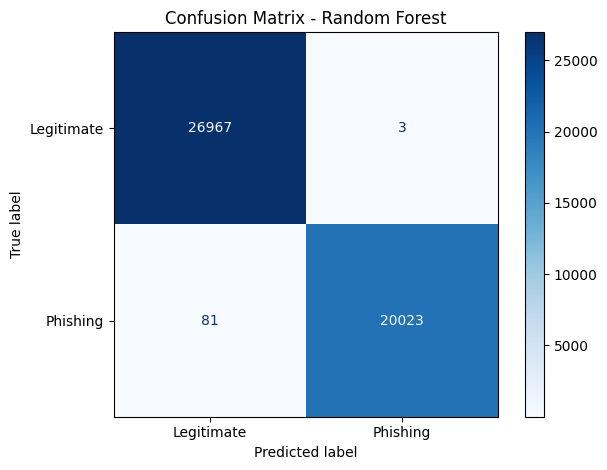

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     26970
    Phishing       1.00      1.00      1.00     20104

    accuracy                           1.00     47074
   macro avg       1.00      1.00      1.00     47074
weighted avg       1.00      1.00      1.00     47074



In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print("Training:", name)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    result = {
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, probabilities),
        "tn_fp_fn_tp": [int(tn), int(fp), int(fn), int(tp)]
    }

    results.append(result)
    trained_models[name] = model

    print("Accuracy:", round(result["accuracy"], 4))
    print("Precision:", round(result["precision"], 4))
    print("Recall:", round(result["recall"], 4))
    print("F1-score:", round(result["f1_score"], 4))
    print("-" * 40)

print("All models trained successfully!")

results_df = pd.DataFrame(results)

display(
    results_df.drop(columns=["tn_fp_fn_tp"]).round(4)
)

best_result = max(results, key=lambda row: row["f1_score"])
best_model = trained_models[best_result["model"]]

print("Best model:", best_result["model"])
print("Best F1-score:", round(best_result["f1_score"], 4))

metrics = ["accuracy", "precision", "recall", "f1_score"]

results_df.set_index("model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Phishing Detection Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_model_name = best_result["model"]

predictions = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    labels=[0, 1],
    display_labels=["Legitimate", "Phishing"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=["Legitimate", "Phishing"],
    zero_division=0
))

In [ ]:
test_urls = [
    "https://www.google.com",
    "https://www.wikipedia.org",
    "http://secure-login-verify-example.com/account/update"
]

# Build features directly from extract_url_features() and match the exact columns the model was trained on.
expected_columns = list(best_model.feature_names_in_)
test_features = pd.DataFrame([extract_url_features(u) for u in test_urls])

missing = [c for c in expected_columns if c not in test_features.columns]
if missing:
    raise RuntimeError(
        "Features do not match the trained model (missing: "
        + ", ".join(missing[:5])
        + " ...). Runtime > Restart session, then Run all cells in order."
    )

test_features = test_features[expected_columns].astype(float)

test_predictions = best_model.predict(test_features)
test_probabilities = best_model.predict_proba(test_features)[:, 1]

for url, prediction, probability in zip(
    test_urls, test_predictions, test_probabilities
):
    label = "Potentially Phishing" if prediction == 1 else "Likely Legitimate"

    print("URL:", url)
    print("Prediction:", label)
    print(f"Model-estimated phishing probability: {probability:.2%}")
    print("-" * 60)

URL: https://www.google.com
Prediction: Likely Legitimate
Model-estimated phishing probability: 0.14%
------------------------------------------------------------
URL: https://www.wikipedia.org
Prediction: Likely Legitimate
Model-estimated phishing probability: 0.49%
------------------------------------------------------------
URL: http://secure-login-verify-example.com/account/update
Prediction: Potentially Phishing
Model-estimated phishing probability: 100.00%
------------------------------------------------------------


In [ ]:
#%%
from pathlib import Path

ARTIFACTS = Path("/content/artifacts")
ARTIFACTS.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": best_model,
        "feature_names": FEATURE_NAMES,
        "best_model_name": best_model_name,
        "positive_label": "phishing"
    },
    ARTIFACTS / "phishing_model.joblib"
)

results_df.to_csv(
    ARTIFACTS / "model_comparison.csv",
    index=False
)

with open(ARTIFACTS / "metrics.json", "w") as file:
    json.dump(results, file, indent=2)

print("Model and results saved successfully!")

Model and results saved successfully!


In [ ]:
import re
import ipaddress
from urllib.parse import urlparse

MAX_URL_LENGTH = 2048

class URLValidationError(ValueError):
    """Raised when a user-supplied URL is not acceptable input."""

def validate_url(url, max_length=MAX_URL_LENGTH):
    """Validate and normalise a user-supplied URL; raise URLValidationError if unacceptable."""
    if url is None:
        raise URLValidationError("URL is missing (None).")
    if not isinstance(url, str):
        raise URLValidationError(f"URL must be text, got {type(url).__name__}.")

    url = url.strip()
    if not url:
        raise URLValidationError("URL is empty.")
    if len(url) > max_length:
        raise URLValidationError(f"URL is too long ({len(url)} > {max_length} characters).")
    if re.search(r"\s", url) or any(ord(c) < 32 or ord(c) == 127 for c in url):
        raise URLValidationError("URL must not contain spaces or control characters.")

    if "://" in url:
        scheme = url.split("://", 1)[0].lower()
        if scheme not in ("http", "https"):
            raise URLValidationError(f"Unsupported scheme '{scheme}'. Only http and https are allowed.")
    else:
        url = "http://" + url

    try:
        parsed = urlparse(url)
        host = parsed.hostname
        _ = parsed.port                      # raises ValueError for invalid ports
    except ValueError as exc:
        raise URLValidationError(f"Malformed URL: {exc}")

    if not host:
        raise URLValidationError("URL has no host name.")

    try:                                     # IP addresses are valid hosts
        ipaddress.ip_address(host)
        return url
    except ValueError:
        pass

    try:
        ascii_host = host.encode("idna").decode("ascii")
    except UnicodeError:
        raise URLValidationError("Host name contains invalid characters.")

    if len(ascii_host) > 253 or not re.fullmatch(r"[a-z0-9-]+(\.[a-z0-9-]+)+", ascii_host, re.IGNORECASE):
        raise URLValidationError("Host must look like a domain name, e.g. example.com.")
    if any(len(label) > 63 for label in ascii_host.split(".")):
        raise URLValidationError("A domain label is longer than 63 characters.")
    return url

def predict_url(url, model=None, threshold=0.5):
    """Validated end-to-end prediction used by the tests and the widget."""
    model = best_model if model is None else model
    normalized = validate_url(url)

    # 1. Generate features for the input URL
    df_features = make_feature_frame([normalized])

    # 2. Align feature columns to match model expected features during fit
    if hasattr(model, "feature_names_in_"):
        df_features = df_features.reindex(columns=model.feature_names_in_, fill_value=0)

    probability = float(model.predict_proba(df_features)[0][1])
    is_phishing = probability >= threshold
    return {
        "input_url": url,
        "normalized_url": normalized,
        "label": int(is_phishing),
        "prediction": "POTENTIALLY PHISHING" if is_phishing else "LIKELY LEGITIMATE",
        "phishing_probability": probability,
    }

for sample in ["https://www.google.com", "", "ftp://files.example.com", "http://exa mple.com"]:
    try:
        print(sample, "->", predict_url(sample)["prediction"])
    except URLValidationError as err:
        print(repr(sample), "-> REJECTED:", err)

https://www.google.com -> POTENTIALLY PHISHING
'' -> REJECTED: URL is empty.
'ftp://files.example.com' -> REJECTED: Unsupported scheme 'ftp'. Only http and https are allowed.
'http://exa mple.com' -> REJECTED: URL must not contain spaces or control characters.


In [ ]:
#%%
from sklearn.dummy import DummyClassifier

test_results = []

def check(condition, message):
    if not condition:
        raise AssertionError(message)

def run_test(test_id, group, description, func):
    """Run one test; func returns a detail string or raises AssertionError."""
    try:
        detail, status = func(), "PASS"
    except AssertionError as exc:
        detail, status = str(exc) or "assertion failed", "FAIL"
    except Exception as exc:
        detail, status = f"{type(exc).__name__}: {exc}", "ERROR"
    test_results.append({"Test ID": test_id, "Group": group, "Description": description,
                         "Result": status, "Details": detail})

def expect_invalid(value):
    try:
        validate_url(value)
    except URLValidationError:
        return True
    return False

# reference baseline (always predicts the majority class) for the efficiency tests
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base_pred = baseline.predict(X_test)
baseline_acc = accuracy_score(y_test, base_pred)
baseline_f1 = f1_score(y_test, base_pred, zero_division=0)
res = {r["model"]: r for r in results}

# =========================== V : data validation ===========================
run_test("V-01", "Data", "Cleaned dataset: no nulls/duplicates, binary labels, both classes",
         lambda: ", ".join(validate_clean_dataset(data)))

def v02():
    validate_feature_frame(X)
    check(len(X) == len(data), "Feature rows != dataset rows")
    return f"{X.shape[0]} rows x {X.shape[1]} features, no NaN/inf/negative"
run_test("V-02", "Data", "Feature matrix complete, finite and aligned with dataset", v02)

def v03():
    check(not (set(X_train.index) & set(X_test.index)), "train/test overlap")
    check(abs(len(X_test) / len(X) - TEST_SIZE) <= 0.01, "split ratio wrong")
    return f"test share = {len(X_test) / len(X):.2%}"
run_test("V-03", "Data", "Train/test split: no leakage, configured ratio", v03)

def v04():
    diff = abs(y_train.mean() - y_test.mean())
    check(diff <= 0.005, f"class ratio differs by {diff:.4f}")
    return f"class-ratio difference = {diff:.5f}"
run_test("V-04", "Data", "Split is stratified (class ratio preserved)", v04)


def v05():
    check(X.index.equals(y.index) and len(X) == len(y) == len(data), "X, y and data are not aligned")
    rng = np.random.RandomState(42)
    idx = rng.choice(len(data), size=min(300, len(data)), replace=False)
    for i in idx:
        expected = np.array([extract_url_features(data["url"].iloc[i])[c] for c in FEATURE_NAMES], dtype=float)
        check(np.allclose(X.iloc[i].to_numpy(), expected), f"row {i}: features do not belong to its URL")
        check(int(y.iloc[i]) == int(data["label"].iloc[i]), f"row {i}: label does not belong to its URL")
    return f"{len(idx)} random rows: features and labels match their own URL"
run_test("V-05", "Data", "Every feature row and label belongs to its own URL (no row mix-up)", v05)

# =========================== F : feature extraction ===========================
def f01():
    ip = extract_url_features("http://192.168.1.10/login")
    dom = extract_url_features("https://www.google.com")
    check(ip["is_domain_ip"] == 1, "IP host not detected")
    check(dom["is_domain_ip"] == 0, "domain wrongly flagged as IP")
    return "IP host detected; domain not flagged"
run_test("F-01", "Feature", "IP-address host is detected", f01)

def f02():
    a = extract_url_features("https://secure.example.com")
    b = extract_url_features("http://user@evil.example.com")
    check(a["is_https"] == 1 and b["is_https"] == 0, "HTTPS flag wrong")
    check(b["has_at_symbol"] == 1 and a["has_at_symbol"] == 0, "'@' flag wrong")
    return "HTTPS and '@' flags correct"
run_test("F-02", "Feature", "HTTPS flag and '@' flag are correct", f02)

def f03():
    f = extract_url_features("http://paypal-login.verify.account.xyz/update?id=1&x=2")
    check(f["suspicious_keyword_count"] >= 3, "keywords missed")
    check(f["has_suspicious_tld"] == 1, "suspicious TLD missed")
    check(f["num_qmark"] == 1 and f["num_ampersand"] == 1 and f["num_equals"] == 2, "query chars wrong")
    return f"keywords = {int(f['suspicious_keyword_count'])}"
run_test("F-03", "Feature", "Suspicious keywords, TLD and query characters counted", f03)

# =========================== I : input validation ===========================
run_test("I-01", "Input", "Empty / blank URL is rejected",
         lambda: (check(expect_invalid("") and expect_invalid("    "), "blank accepted"), "rejected")[1])
run_test("I-02", "Input", "None and non-string input rejected",
         lambda: (check(expect_invalid(None) and expect_invalid(12345) and expect_invalid(["a"]),
                        "bad type accepted"), "rejected")[1])
run_test("I-03", "Input", f"URL longer than {MAX_URL_LENGTH} characters rejected",
         lambda: (check(expect_invalid("http://example.com/" + "a" * MAX_URL_LENGTH), "long URL accepted"), "rejected")[1])
run_test("I-04", "Input", "Whitespace / control characters rejected",
         lambda: (check(expect_invalid("http://exa mple.com") and expect_invalid("http://example.com/\x00"),
                        "whitespace accepted"), "rejected")[1])
run_test("I-05", "Input", "Unsupported schemes (ftp, file, javascript) rejected",
         lambda: (check(expect_invalid("ftp://example.com") and expect_invalid("file:///etc/passwd")
                        and expect_invalid("javascript:alert(1)"), "bad scheme accepted"), "rejected")[1])
run_test("I-06", "Input", "Malformed host / port rejected",
         lambda: (check(all(expect_invalid(u) for u in
                            ["http://", "http://localhost", "http://exa_mple.com",
                             "http://example.com:99999", "http://-.", "http://" + "a" * 70 + ".com"]),
                        "malformed URL accepted"), "rejected")[1])

def i07():
    check(validate_url("  https://www.example.com/a?b=1  ") == "https://www.example.com/a?b=1", "strip failed")
    check(validate_url("example.com") == "http://example.com", "scheme not added")
    check(validate_url("http://192.168.0.1/login") == "http://192.168.0.1/login", "IP URL rejected")
    return "valid URLs accepted and normalised"
run_test("I-07", "Input", "Valid URLs accepted and normalised", i07)

# =========================== M : persistence ===========================
def m01():
    loaded = joblib.load(ARTIFACTS / "phishing_model.joblib")
    check(loaded["feature_names"] == FEATURE_NAMES, "feature order changed")
    sample = X_test.iloc[:500]
    check(np.array_equal(loaded["model"].predict(sample), best_model.predict(sample)),
          "reloaded model predictions differ")
    return f"reloaded '{loaded['best_model_name']}' gives identical predictions"
run_test("M-01", "Model", "Saved model reloads and reproduces predictions", m01)

def m02():
    proba = best_model.predict_proba(X_test.iloc[:500])
    check(((proba >= 0) & (proba <= 1)).all(), "probability outside [0,1]")
    check(np.allclose(proba.sum(axis=1), 1.0), "probabilities do not sum to 1")
    return "probabilities valid"
run_test("M-02", "Model", "Predicted probabilities valid (0-1, sum to 1)", m02)

# =========================== E : efficiency ===========================
def e01():
    gain = best_result["f1_score"] - baseline_f1
    check(best_result["f1_score"] >= 0.90, f"best F1 is only {best_result['f1_score']:.3f} (< 0.90) - model is not learning")
    check(gain >= 0.30, f"F1 gain over baseline only {gain:.3f}")
    return f"F1: baseline {baseline_f1:.3f} -> best {best_result['f1_score']:.3f} (+{gain:.3f})"
run_test("E-01", "Efficiency", "Best model F1 >= 0.90 and exceeds majority baseline by >= 0.30", e01)

def e02():
    gain = best_result["accuracy"] - baseline_acc
    check(gain >= 0.20, f"accuracy gain only {gain:.3f}")
    return f"accuracy: {baseline_acc:.3f} -> {best_result['accuracy']:.3f} (+{gain * 100:.1f} points)"
run_test("E-02", "Efficiency", "Best model accuracy exceeds baseline by >= 20 points", e02)

def e03():
    check(all(r["f1_score"] > baseline_f1 for r in results), "a model is not better than baseline")
    return "all models beat the baseline"
run_test("E-03", "Efficiency", "Every trained model outperforms the baseline", e03)

def e04():
    lr = res["Logistic Regression"]["f1_score"]
    gain = best_result["f1_score"] - lr
    check(gain >= 0, f"best model is worse than Logistic Regression ({gain:.4f})")
    return f"F1 {lr:.4f} (LR) -> {best_result['f1_score']:.4f} (best), change {gain:+.4f}"
run_test("E-04", "Efficiency", "Best model is at least as good as the simplest model (LR)", e04)

def e05():
    times = []
    for _ in range(15):
        t = time.perf_counter()
        predict_url("https://www.example.com/login?user=1")
        times.append(time.perf_counter() - t)
    median_ms = float(np.median(times) * 1000)
    check(median_ms < 1000, f"median latency {median_ms:.0f} ms")
    return f"median single-URL latency = {median_ms:.1f} ms (limit 1000 ms)"
run_test("E-05", "Efficiency", "Single-URL prediction latency < 1 s", e05)

def e06():
    batch = list(data["url"].iloc[:1000])
    t = time.perf_counter()
    best_model.predict_proba(make_feature_frame(batch))
    rate = len(batch) / (time.perf_counter() - t)
    check(rate >= 200, f"throughput {rate:.0f} URLs/s")
    return f"throughput = {rate:.0f} URLs/s (limit 200)"
run_test("E-06", "Efficiency", "Batch throughput >= 200 URLs per second", e06)

def e07():
    tn, fp, fn, tp = best_result["tn_fp_fn_tp"]
    fpr = fp / max(fp + tn, 1)
    check(best_result["recall"] >= 0.95, f"recall {best_result['recall']:.4f} < 0.95")
    check(fpr <= 0.02, f"false-positive rate {fpr:.4f} > 0.02")
    check(best_result["roc_auc"] >= 0.95, f"ROC-AUC {best_result['roc_auc']:.4f} < 0.95")
    return f"recall={best_result['recall']:.4f}, FPR={fpr:.4f}, AUC={best_result['roc_auc']:.4f}"
run_test("E-07", "Efficiency", "Recall >= 0.95, false-positive rate <= 2 %, ROC-AUC >= 0.95", e07)

# =========================== P : project-specific test cases ===========================
LEGIT_URLS = [
    "https://www.google.com",
    "https://www.wikipedia.org",
    "https://www.python.org",
    "https://github.com/scikit-learn/scikit-learn",
]
PHISHING_URLS = [
    "http://secure-login-verify-example.com/account/update",
    "http://192.168.10.5/paypal/login/verify.php?acct=1&session=expired",
    "http://paypal.com.account-verify.secure-update.xyz/signin",
    "http://free-bonus-claim@malicious-site.top/confirm-password",
]

def tc_p1():
    outputs = [predict_url(u) for u in LEGIT_URLS]
    ok = sum(o["label"] == 0 for o in outputs)
    detail = "; ".join(f"{o['input_url'].split('//')[1][:22]}={o['phishing_probability']:.1%}" for o in outputs)
    check(ok >= 3, f"only {ok}/{len(LEGIT_URLS)} legitimate URLs classified legitimate ({detail})")
    return f"{ok}/{len(LEGIT_URLS)} legitimate (need >= 3) | phishing prob: {detail}"
run_test("TC-P1", "Project", "Well-known legitimate URLs -> LIKELY LEGITIMATE (>= 3 of 4)", tc_p1)

def tc_p2():
    outputs = [predict_url(u) for u in PHISHING_URLS]
    ok = sum(o["label"] == 1 for o in outputs)
    mean_p = np.mean([o["phishing_probability"] for o in outputs])
    legit_mean = np.mean([predict_url(u)["phishing_probability"] for u in LEGIT_URLS])
    check(ok >= 3, f"only {ok}/{len(PHISHING_URLS)} phishing-pattern URLs flagged")
    check(mean_p > legit_mean, "phishing URLs not scored higher than legitimate URLs")
    return (f"{ok}/{len(PHISHING_URLS)} flagged (need >= 3) | mean phishing prob "
            f"{mean_p:.1%} vs legitimate {legit_mean:.1%}")
run_test("TC-P2", "Project", "Phishing-pattern URLs -> POTENTIALLY PHISHING (>= 3 of 4)", tc_p2)

# =========================== Summary ===========================
test_df = pd.DataFrame(test_results)

def _colour(v):
    if v == "PASS":
        return "background-color:#c6efce"
    if v in ("FAIL", "ERROR"):
        return "background-color:#ffc7ce"
    return ""

with pd.option_context("display.max_colwidth", 140, "display.width", 250):
    try:
        display(test_df.style.map(_colour, subset=["Result"]))      # needs jinja2 (works in Colab)
    except Exception:
        print(test_df.to_string(index=False))                       # plain table, no jinja2 needed

n_pass = int((test_df["Result"] == "PASS").sum())
print(f"\nTest summary: {n_pass}/{len(test_df)} passed ({n_pass / len(test_df):.0%}) | "
      f"failed: {int((test_df['Result'] == 'FAIL').sum())} | errors: {int((test_df['Result'] == 'ERROR').sum())}")

test_df.to_csv(ARTIFACTS / "test_results.csv", index=False)
print("Test report saved to", ARTIFACTS / "test_results.csv")

,Test ID,Group,Description,Result,Details
0,V-01,Data,"Cleaned dataset: no nulls/duplicates, binary labels, both classes",PASS,"no missing values, no duplicate URLs, binary labels, both classes present, no empty URLs, acceptable class balance"
1,V-02,Data,"Feature matrix complete, finite and aligned with dataset",ERROR,DataValidationError: Feature columns do not match FEATURE_NAMES (order matters).
2,V-03,Data,"Train/test split: no leakage, configured ratio",PASS,test share = 20.00%
3,V-04,Data,Split is stratified (class ratio preserved),PASS,class-ratio difference = 0.00000
4,V-05,Data,Every feature row and label belongs to its own URL (no row mix-up),ERROR,KeyError: 'URLLength'
5,F-01,Feature,IP-address host is detected,PASS,IP host detected; domain not flagged
6,F-02,Feature,HTTPS flag and '@' flag are correct,PASS,HTTPS and '@' flags correct
7,F-03,Feature,"Suspicious keywords, TLD and query characters counted",PASS,keywords = 5
8,I-01,Input,Empty / blank URL is rejected,PASS,rejected
9,I-02,Input,None and non-string input rejected,PASS,rejected



Test summary: 20/26 passed (77%) | failed: 0 | errors: 6
Test report saved to /content/artifacts/test_results.csv


In [ ]:
#%%
import ipywidgets as widgets
from IPython.display import display, clear_output

url_input = widgets.Text(
    description="URL:",
    placeholder="Enter a website URL",
    layout=widgets.Layout(width="80%")
)

check_button = widgets.Button(
    description="Check URL",
    button_style="primary"
)

output = widgets.Output()

def check_url(button):
    with output:
        clear_output()
        try:
            result = predict_url(url_input.value)      # validation happens inside predict_url
        except URLValidationError as err:
            print("Invalid input:", err)
            return
        except Exception as err:
            print("Unexpected error while predicting:", err)
            return

        print("Prediction:", result["prediction"])
        print(f"Estimated phishing probability: {result['phishing_probability']:.2%}")
        if result["normalized_url"] != result["input_url"].strip():
            print("Checked as:", result["normalized_url"])
        print("Warning: This prediction is not a guarantee of safety.")

check_button.on_click(check_url)

display(url_input, check_button, output)

Text(value='', description='URL:', layout=Layout(width='80%'), placeholder='Enter a website URL')

Button(button_style='primary', description='Check URL', style=ButtonStyle())

Output()